In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
folder = Path("C:/Users/jchmo/Downloads/MERGED_CSV/MERGED_CSV")
files = sorted(folder.glob("Merged*.csv"))

In [ ]:
dfs = []

for i in range(1, 64):
    file = folder / f"Merged{i:02d}.csv"

    temp = pd.read_csv(file)

    # Take 10% of each file
    temp = temp.sample(frac=0.05, random_state=42)

    temp["source_file"] = f"Merged{i:02d}"
    
    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

In [4]:
print("Shape:", df.shape)

Shape: (2250961, 40)


In [5]:
print(df["Label"].value_counts())

Label
DDOS-ICMP_FLOOD            345427
DDOS-UDP_FLOOD             259103
DDOS-TCP_FLOOD             214681
DDOS-PSHACK_FLOOD          196169
DDOS-SYN_FLOOD             194216
DDOS-RSTFINFLOOD           193559
DDOS-SYNONYMOUSIP_FLOOD    171675
DOS-UDP_FLOOD              158663
DOS-TCP_FLOOD              127963
DOS-SYN_FLOOD               96913
BENIGN                      52635
MIRAI-GREETH_FLOOD          47406
MIRAI-UDPPLAIN              42567
MIRAI-GREIP_FLOOD           36444
DDOS-ICMP_FRAGMENTATION     21915
VULNERABILITYSCAN           17879
MITM-ARPSPOOFING            14797
DDOS-ACK_FRAGMENTATION      13805
DDOS-UDP_FRAGMENTATION      13675
DNS_SPOOFING                 8566
RECON-HOSTDISCOVERY          6426
RECON-OSSCAN                 4702
RECON-PORTSCAN               3862
DOS-HTTP_FLOOD               3466
DDOS-HTTP_FLOOD              1378
DDOS-SLOWLORIS               1146
DICTIONARYBRUTEFORCE          652
BROWSERHIJACKING              275
SQLINJECTION                  261
COMMANDI

In [6]:
print(df.dtypes)

Header_Length      float64
Protocol Type        int64
Time_To_Live       float64
Rate               float64
fin_flag_number    float64
syn_flag_number    float64
rst_flag_number    float64
psh_flag_number    float64
ack_flag_number    float64
ece_flag_number    float64
cwr_flag_number    float64
ack_count          float64
syn_count          float64
fin_count          float64
rst_count          float64
HTTP               float64
HTTPS              float64
DNS                float64
Telnet             float64
SMTP               float64
SSH                float64
IRC                float64
TCP                float64
UDP                float64
DHCP               float64
ARP                float64
ICMP               float64
IGMP               float64
IPv                float64
LLC                float64
Tot sum            float64
Min                float64
Max                float64
AVG                float64
Std                float64
Tot size           float64
IAT                float64
N

In [7]:
print(df.isna().sum())

Header_Length       0
Protocol Type       0
Time_To_Live        0
Rate                0
fin_flag_number     0
syn_flag_number     0
rst_flag_number     0
psh_flag_number     0
ack_flag_number     0
ece_flag_number     0
cwr_flag_number     0
ack_count           0
syn_count           0
fin_count           0
rst_count           0
HTTP                0
HTTPS               0
DNS                 0
Telnet              0
SMTP                0
SSH                 0
IRC                 0
TCP                 0
UDP                 0
DHCP                0
ARP                 0
ICMP                0
IGMP                0
IPv                 0
LLC                 0
Tot sum             0
Min                 0
Max                 0
AVG                 0
Std                17
Tot size            0
IAT                 0
Number              0
Variance           17
Label               0
dtype: int64


In [8]:
print(df.nunique())

Header_Length        1645
Protocol Type           5
Time_To_Live         8741
Rate               220901
fin_flag_number       175
syn_flag_number       250
rst_flag_number       197
psh_flag_number       247
ack_flag_number       361
ece_flag_number        19
cwr_flag_number        13
ack_count             101
syn_count             101
fin_count             101
rst_count             101
HTTP                  174
HTTPS                 244
DNS                   196
Telnet                  7
SMTP                    8
SSH                    21
IRC                     7
TCP                   357
UDP                   360
DHCP                   40
ARP                   205
ICMP                  291
IGMP                    9
IPv                   205
LLC                   205
Tot sum             45755
Min                   654
Max                  3467
AVG                 48349
Std                205146
Tot size            48349
IAT                223412
Number                100
Variance    

In [9]:
print("Total rows:", len(df))
print("Number of classes:", df["Label"].nunique())

print("\nClass distribution:")
print(df["Label"].value_counts())

Total rows: 2250961
Number of classes: 34

Class distribution:
Label
DDOS-ICMP_FLOOD            345427
DDOS-UDP_FLOOD             259103
DDOS-TCP_FLOOD             214681
DDOS-PSHACK_FLOOD          196169
DDOS-SYN_FLOOD             194216
DDOS-RSTFINFLOOD           193559
DDOS-SYNONYMOUSIP_FLOOD    171675
DOS-UDP_FLOOD              158663
DOS-TCP_FLOOD              127963
DOS-SYN_FLOOD               96913
BENIGN                      52635
MIRAI-GREETH_FLOOD          47406
MIRAI-UDPPLAIN              42567
MIRAI-GREIP_FLOOD           36444
DDOS-ICMP_FRAGMENTATION     21915
VULNERABILITYSCAN           17879
MITM-ARPSPOOFING            14797
DDOS-ACK_FRAGMENTATION      13805
DDOS-UDP_FRAGMENTATION      13675
DNS_SPOOFING                 8566
RECON-HOSTDISCOVERY          6426
RECON-OSSCAN                 4702
RECON-PORTSCAN               3862
DOS-HTTP_FLOOD               3466
DDOS-HTTP_FLOOD              1378
DDOS-SLOWLORIS               1146
DICTIONARYBRUTEFORCE          652
BROWSERHIJACK

In [11]:
print(df.columns.to_list())

['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Label']


In [13]:
# Copy dataframe so we don't accidentally modify the original
eda = df.copy()

# Binary label for exploratory comparison
eda["Traffic_Type"] = np.where(
    eda["Label"] == "BENIGN",
    "BENIGN",
    "MALICIOUS"
)

print(eda["Traffic_Type"].value_counts())
print(eda["Traffic_Type"].value_counts(normalize=True) * 100)

Traffic_Type
MALICIOUS    2198326
BENIGN         52635
Name: count, dtype: int64
Traffic_Type
MALICIOUS    97.661665
BENIGN        2.338335
Name: proportion, dtype: float64


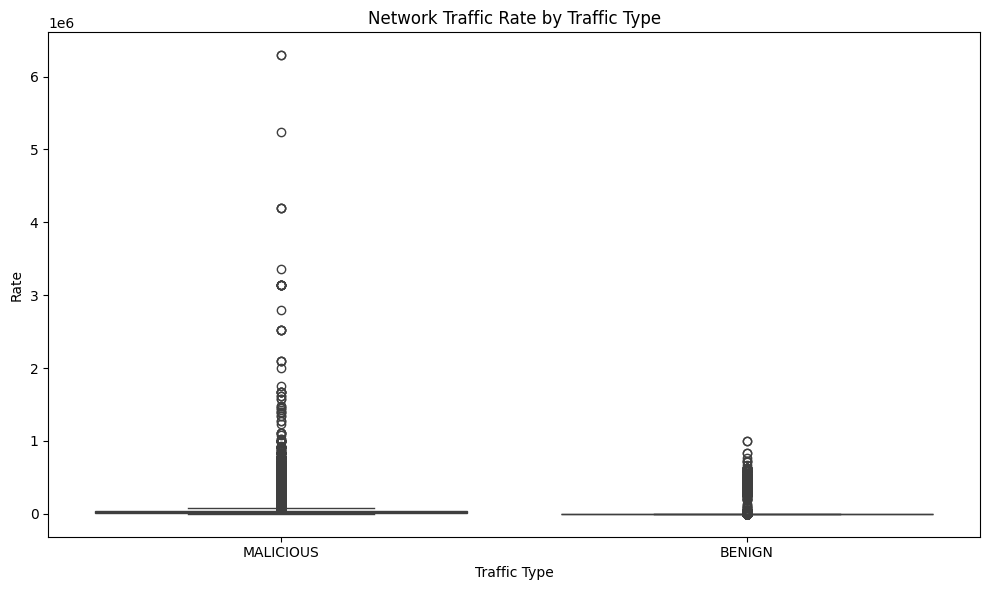

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=eda,
    x="Traffic_Type",
    y="Rate"
)

plt.title("Network Traffic Rate by Traffic Type")
plt.xlabel("Traffic Type")
plt.ylabel("Rate")
plt.tight_layout()
plt.show()

In [21]:
tcp_flags = [
    "fin_flag_number",
    "syn_flag_number",
    "rst_flag_number",
    "psh_flag_number",
    "ack_flag_number",
    "ece_flag_number",
    "cwr_flag_number"
]

In [22]:
flag_means = (
    eda.groupby("Traffic_Type")[tcp_flags]
    .mean()
    .T
)

flag_means

Traffic_Type,BENIGN,MALICIOUS
fin_flag_number,0.011071,0.088704
syn_flag_number,0.013881,0.210619
rst_flag_number,0.001921,0.095113
psh_flag_number,0.161884,0.092296
ack_flag_number,0.804421,0.113725
ece_flag_number,0.000391,0.000019
cwr_flag_number,0.000199,0.000010


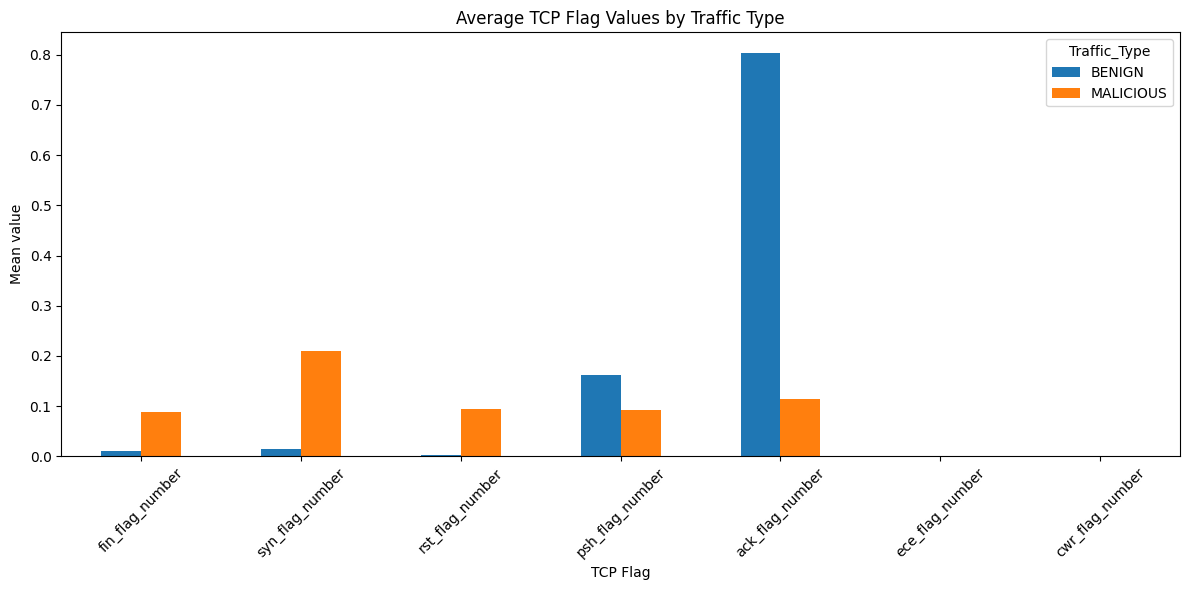

In [23]:
flag_means.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average TCP Flag Values by Traffic Type")
plt.xlabel("TCP Flag")
plt.ylabel("Mean value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
packet_features = [
    "Tot size",
    "Min",
    "Max",
    "AVG",
    "Std",
    "Variance"
]

In [31]:
traffic_type = (eda.groupby("Traffic_Type")[packet_features].agg(
    ["mean", "median", "std", "min", "max"]
).T)

<Axes: >

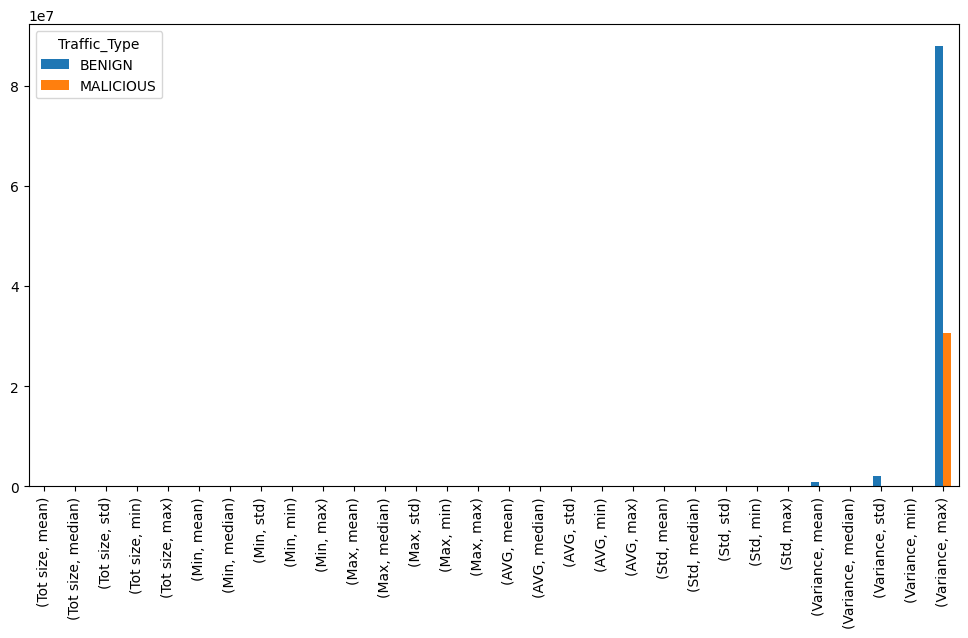

In [32]:
traffic_type.plot(
    kind="bar",
    figsize=(12, 6)
)